In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [1]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi


Bad key "text.kerning_factor" on line 4 in
/home/wx2203/anaconda3/lib/python3.7/site-packages/matplotlib/mpl-data/stylelib/_classic_test_patch.mplstyle.
You probably need to get an updated matplotlibrc file from
http://github.com/matplotlib/matplotlib/blob/master/matplotlibrc.template
or from the matplotlib source distribution


# 1. spontaneous running

```
% day2 runCDE 5min
% day3 runBCD 5min
% -------- rig turned 90 ---------
% day4 runBC 10min
% day5 runCD 10min
% day6 runBCDEG 10min
```

In [2]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or '/scratch/' for s1n3/4
# neural_root = str(STEPS / "step_2") + "/"
# step_0_root = str(STEPS / "step_0") + "/"
# rotary_root = '/home/wx2203/RS_analysis/H_b_new/'
# mid_product_root = '/home/wx2203/RS_analysis/behavior2/trash'
# dlc_root = '/home/wx2203/RS_analysis/DLC/'
# whisk_dlc_root = '/home/wx2203/Weihao/analysis/DLC/'
# pupil_path = '/home/wx2203/RS_analysis/DLC/updated_pupil/pupil_125_07042020.mat'
# mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'
# groom_dlc_root = '/home/wx2203/Weihao/behavior_locker/body_dlc/'
# config_root = '/home/wx2203/Weihao/data_locker/step_0/'
# mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'

analysis_root = prefix+'users/wx2203/new_analysis_locker/'
# config_path = analysis_root+'dlc-locker/all-config/'
whiskey_path = analysis_root+'dlc-locker/whiskey/'
body_path = analysis_root+'dlc-locker/body/'
neural_path = analysis_root+'data-locker/analysis/step_1/'
step_0_root = analysis_root+'data-locker/analysis/step_0/'

In [3]:
mouse = 'cm193'
f1 = [f for f in glob.glob(neural_path + mouse+"/[2]/run[CDE]*.mat", recursive=True)] 
f2 = [f for f in glob.glob(neural_path + mouse+"/[3]/run[BCD]*.mat", recursive=True)]
f3 = [f for f in glob.glob(neural_path + mouse+"/[4]/run[BC]*.mat", recursive=True)]
f4 = [f for f in glob.glob(neural_path + mouse+"/[5]/run[C-D]*.mat", recursive=True)]
f5 = [f for f in glob.glob(neural_path + mouse+"/[6]/run[B-E]*.mat", recursive=True)]
f6 = [f for f in glob.glob(neural_path + mouse+"/[6]/run[G]*.mat", recursive=True)]

file_spont = f1+f2+f3+f4+f5+f6
file_spont

['/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/2/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/2/runE_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/2/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/3/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/3/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/3/runB_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/4/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/4/runB_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/5/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_1/cm193/

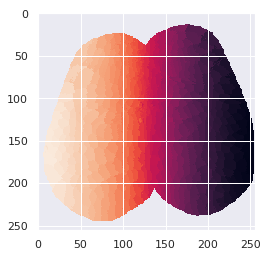

In [4]:
with h5py.File(step_0_root+'idx_sorted_500_cm193.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [5]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

In [9]:
step_0_root+'crop_groom_'+mouse+'.mat'

'/mnt/staging/users/wx2203/new_analysis_locker/data-locker/analysis/step_0/crop_groom_cm193.mat'

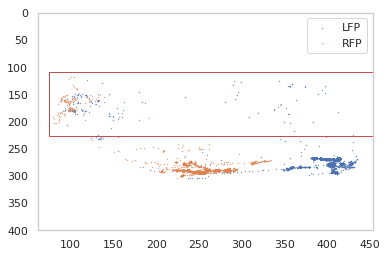

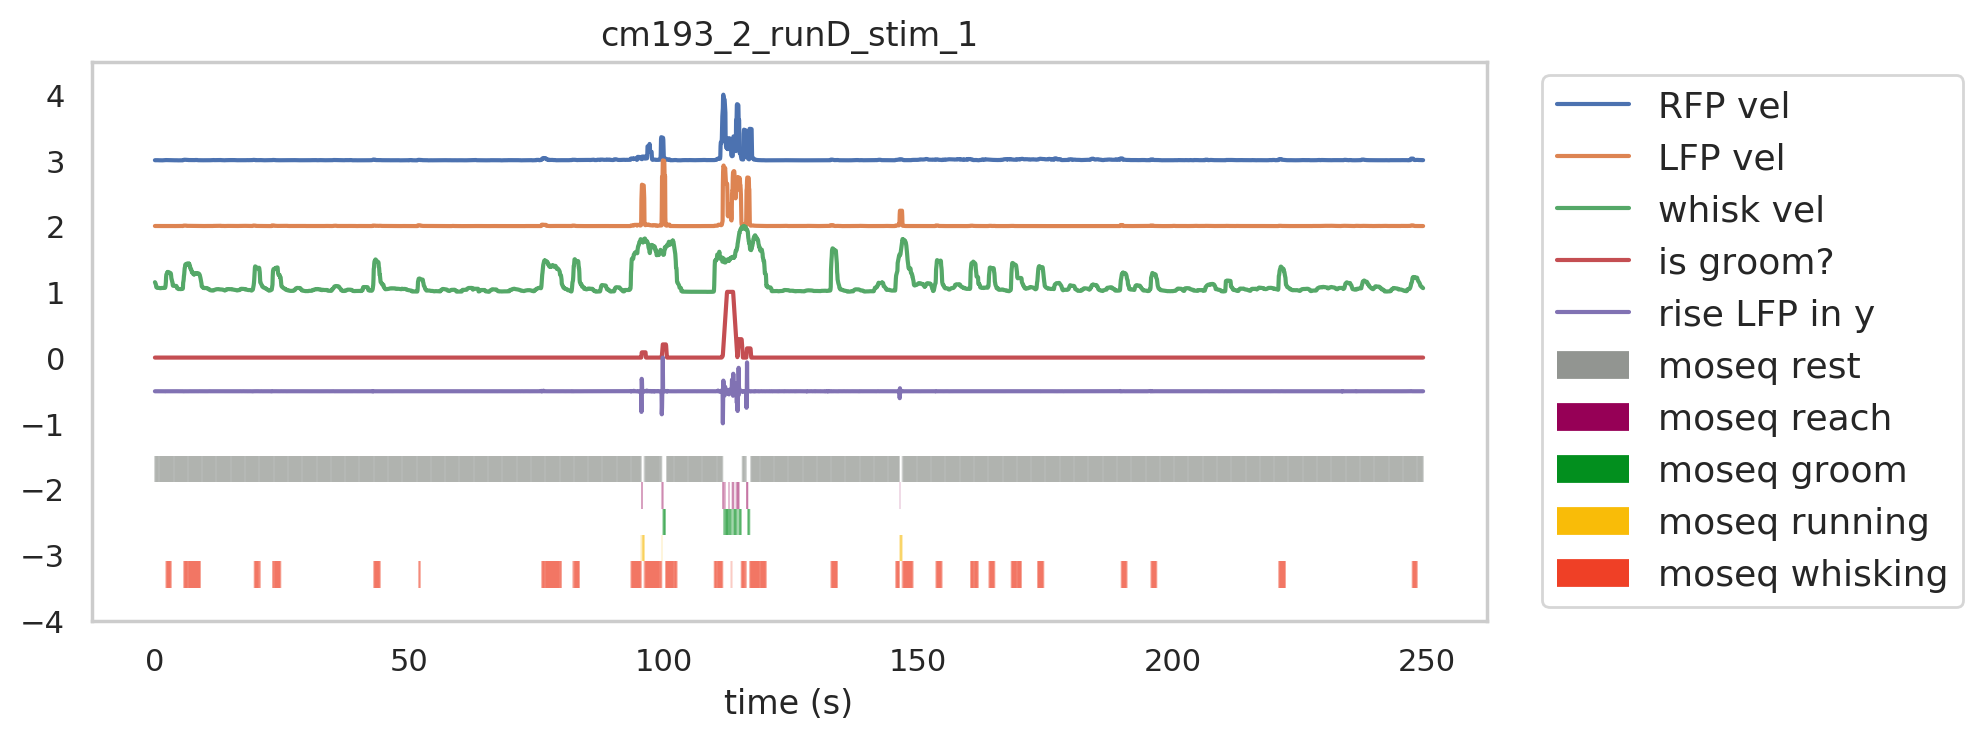

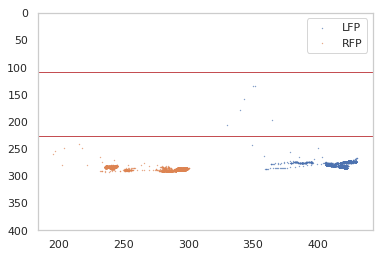

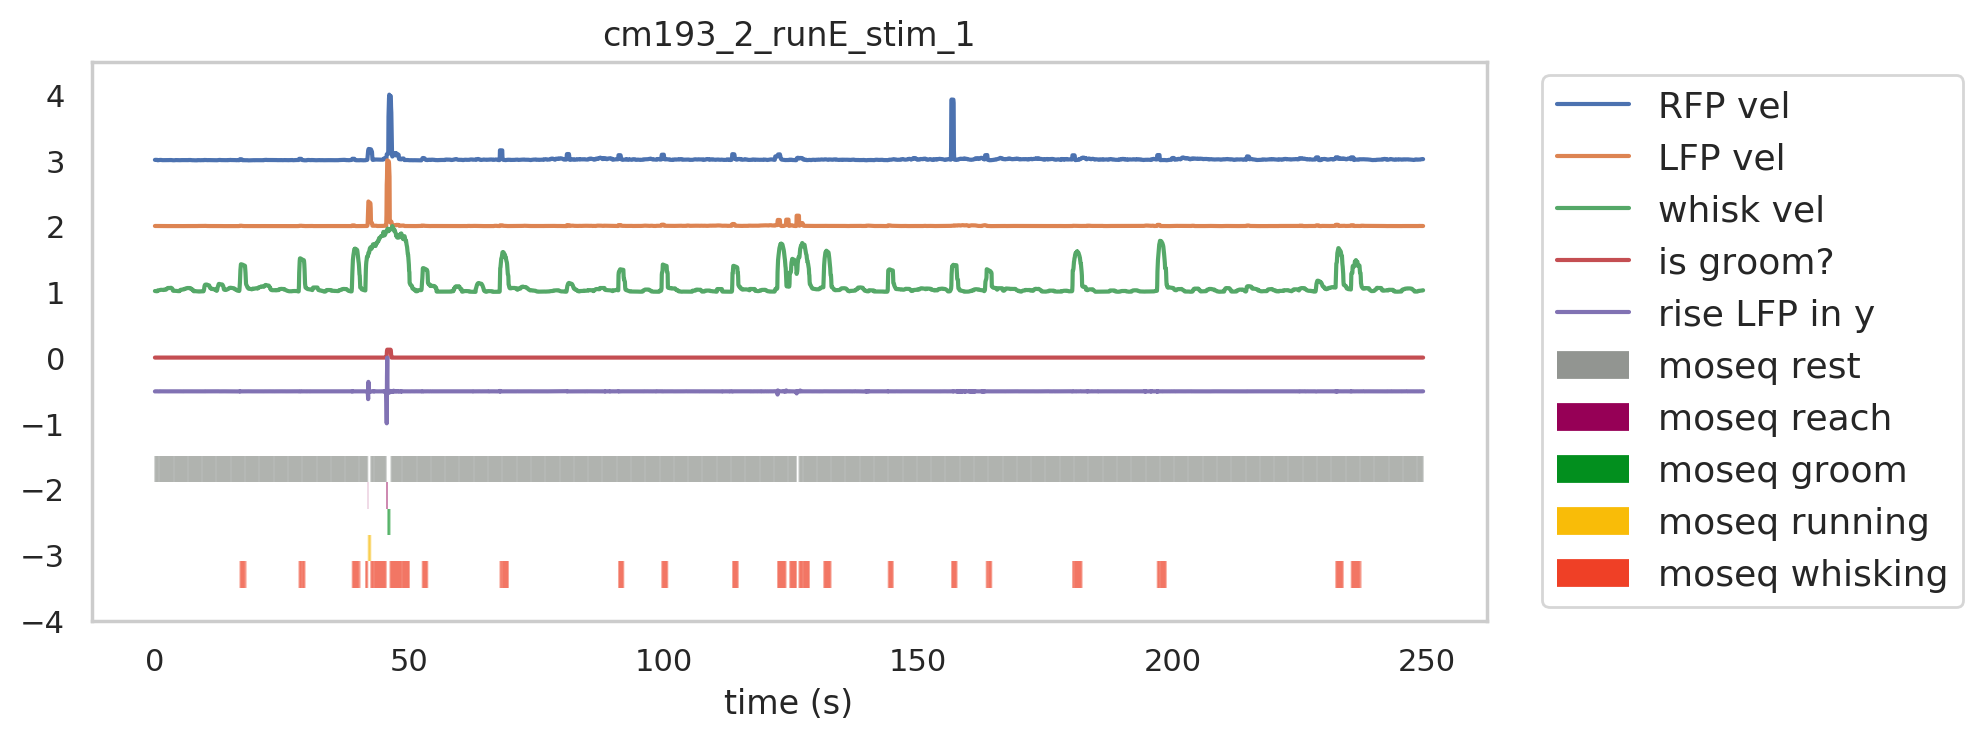

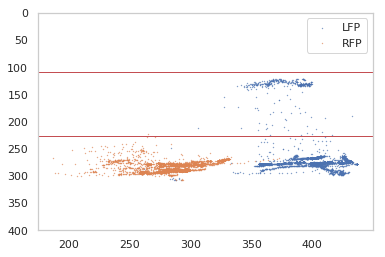

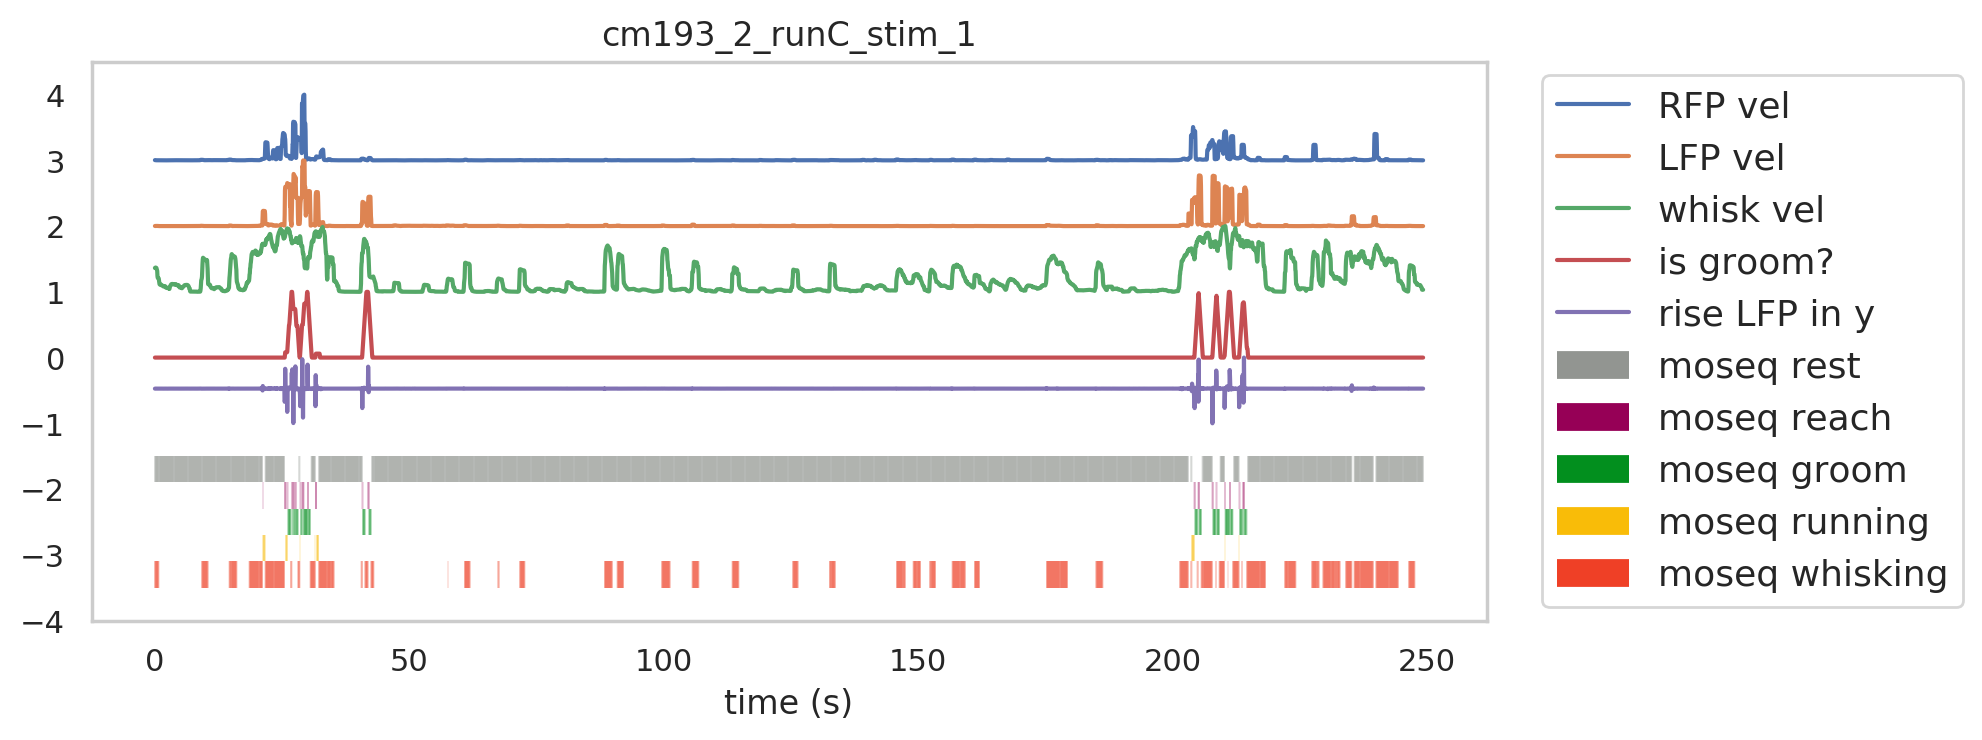

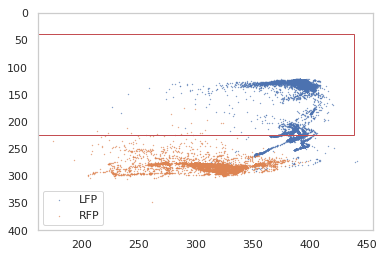

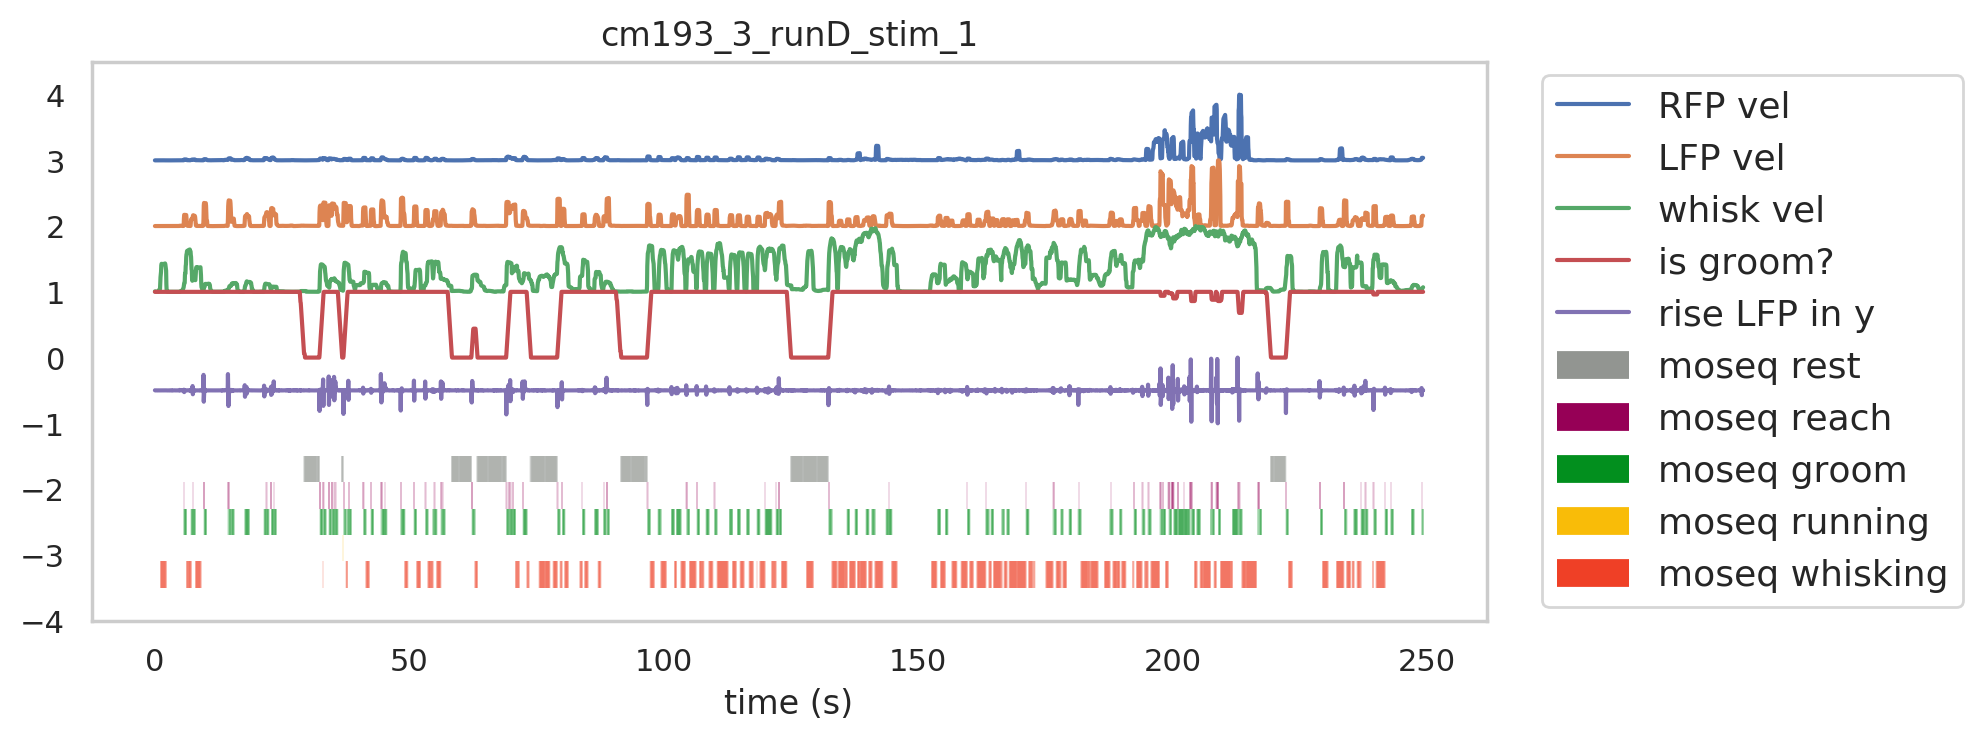

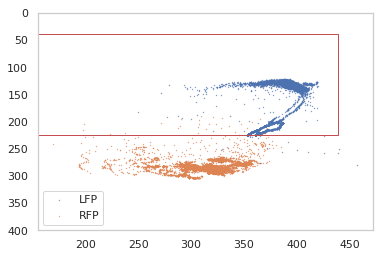

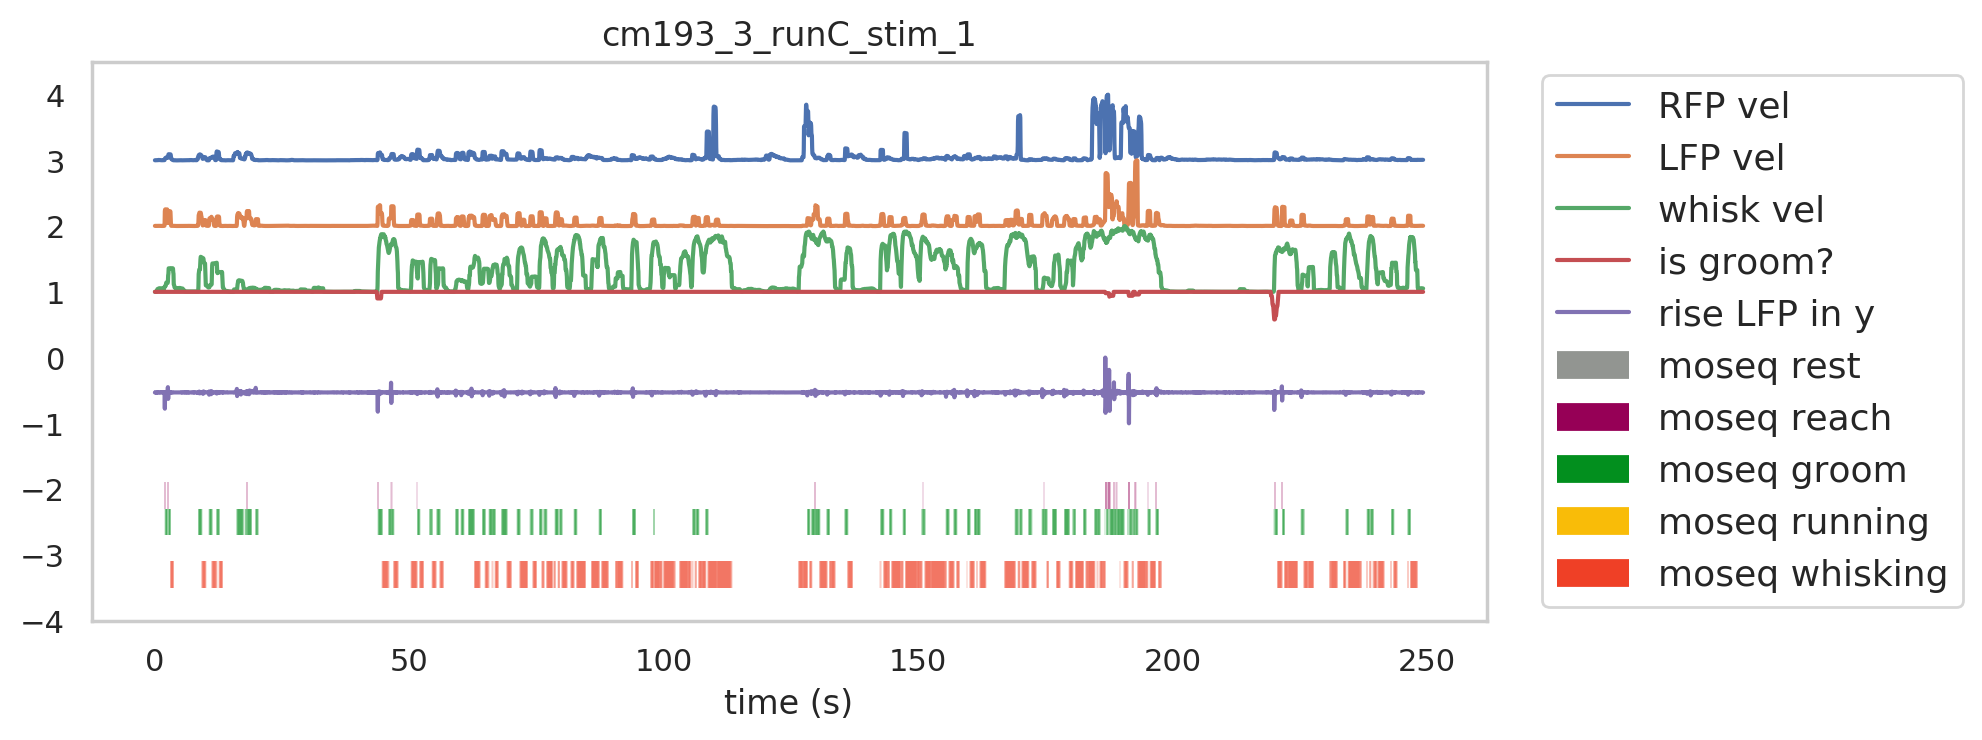

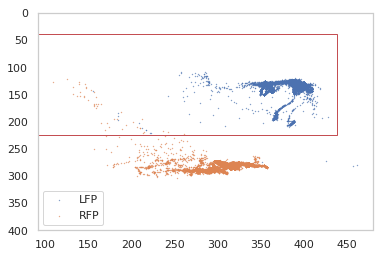

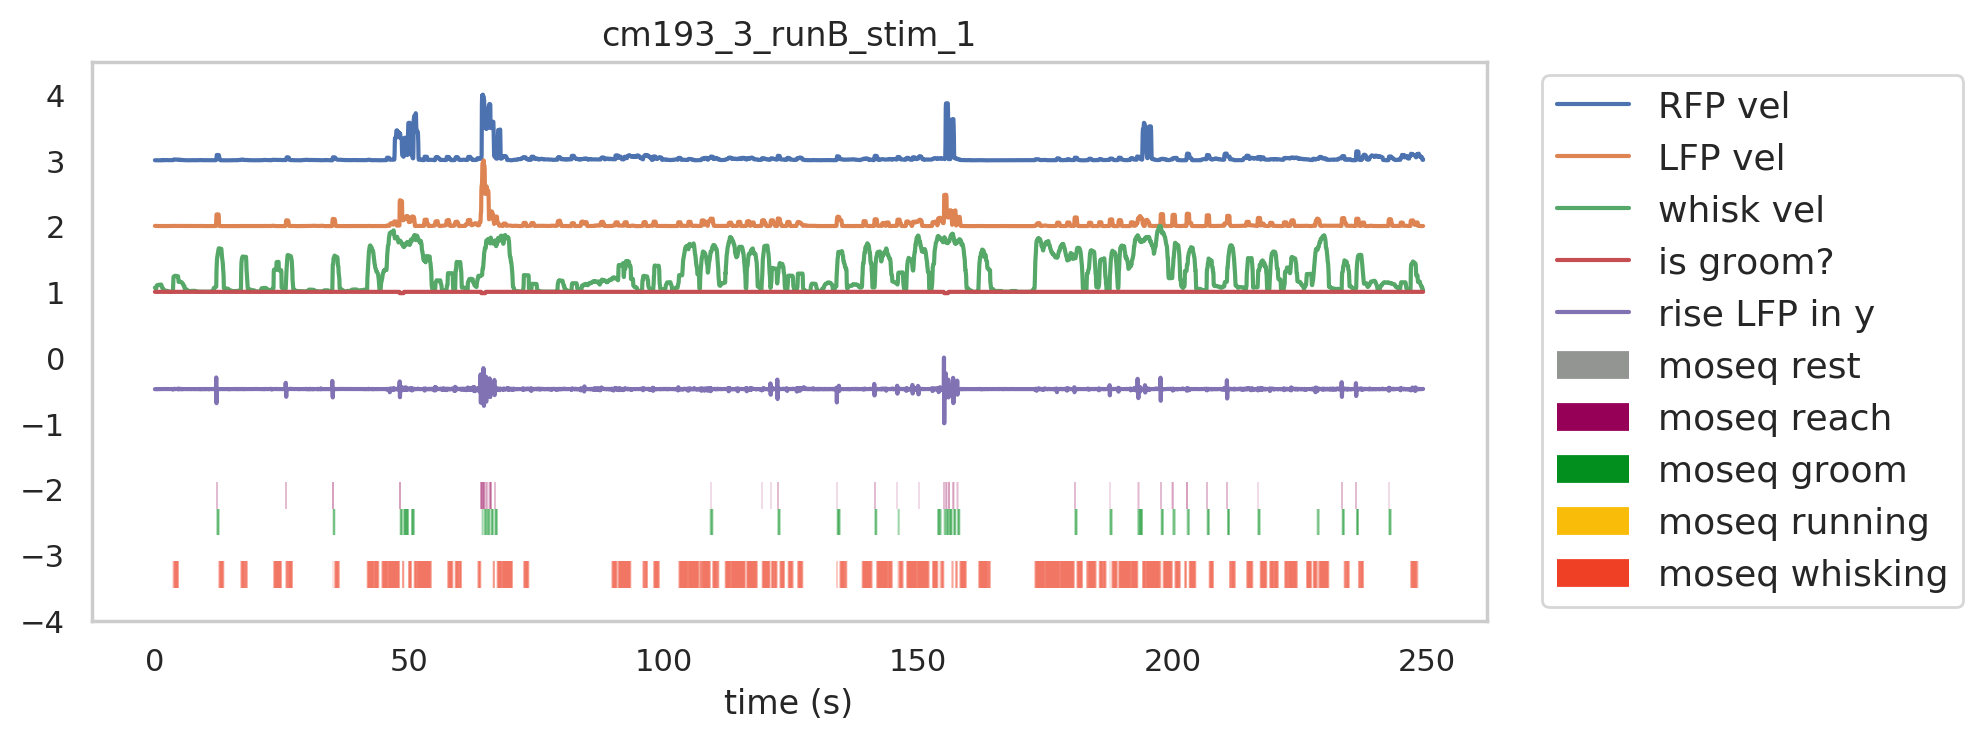

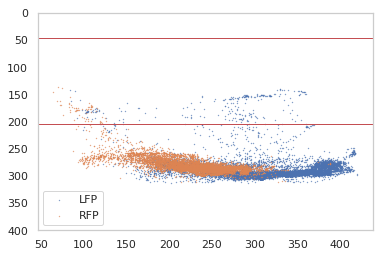

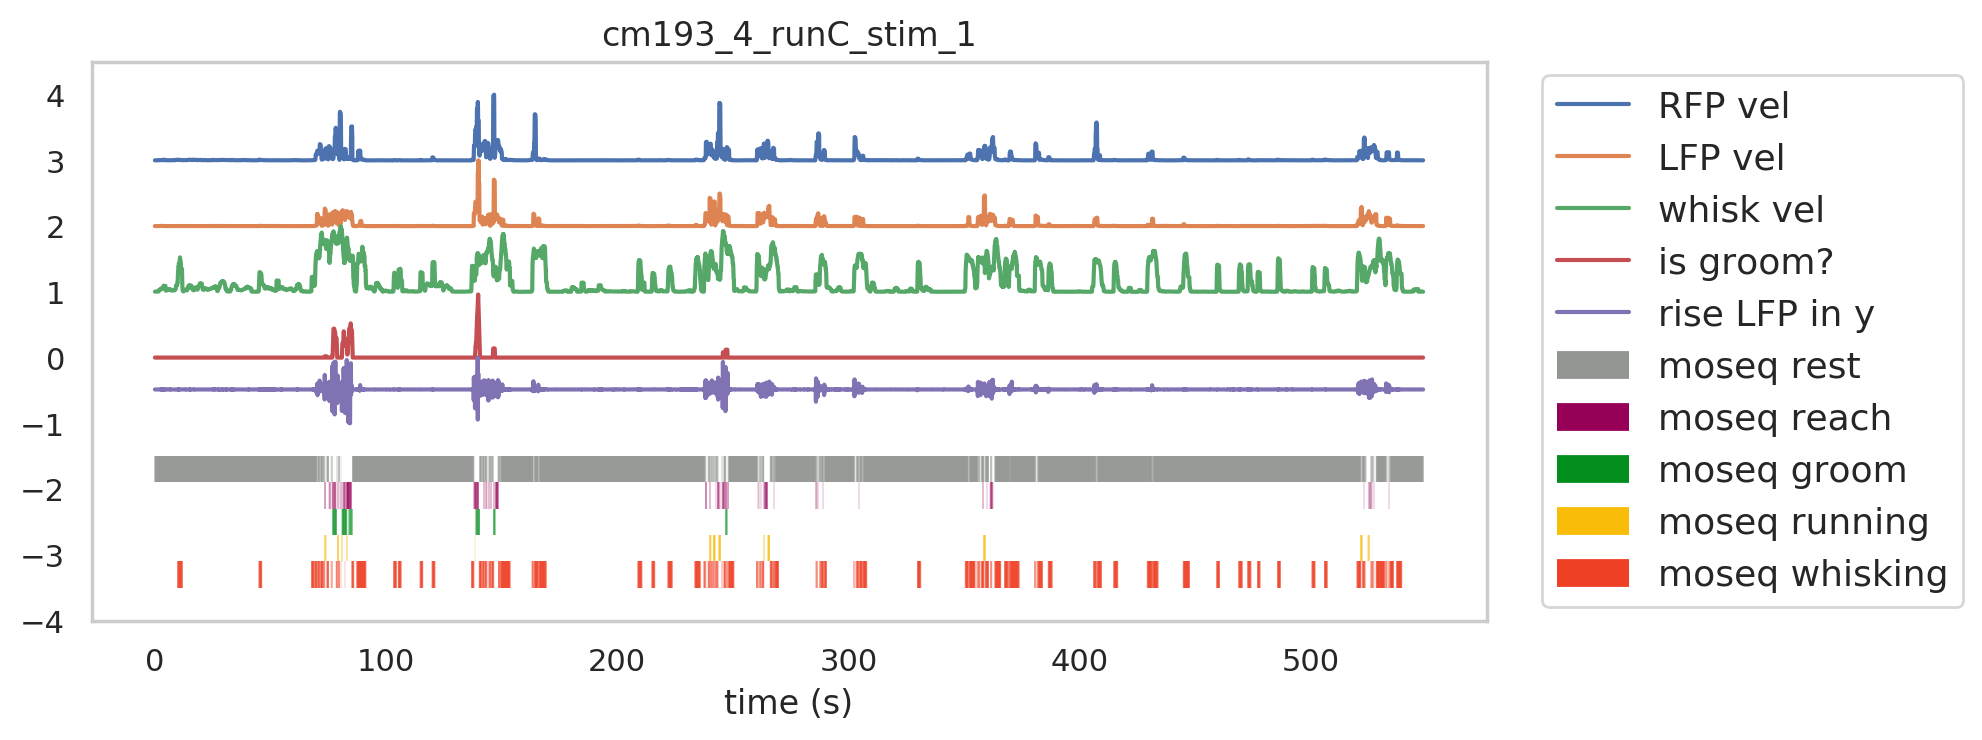

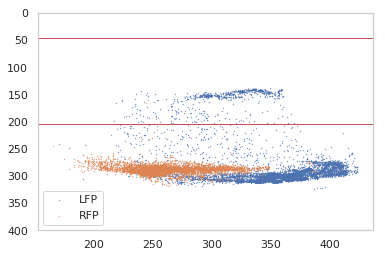

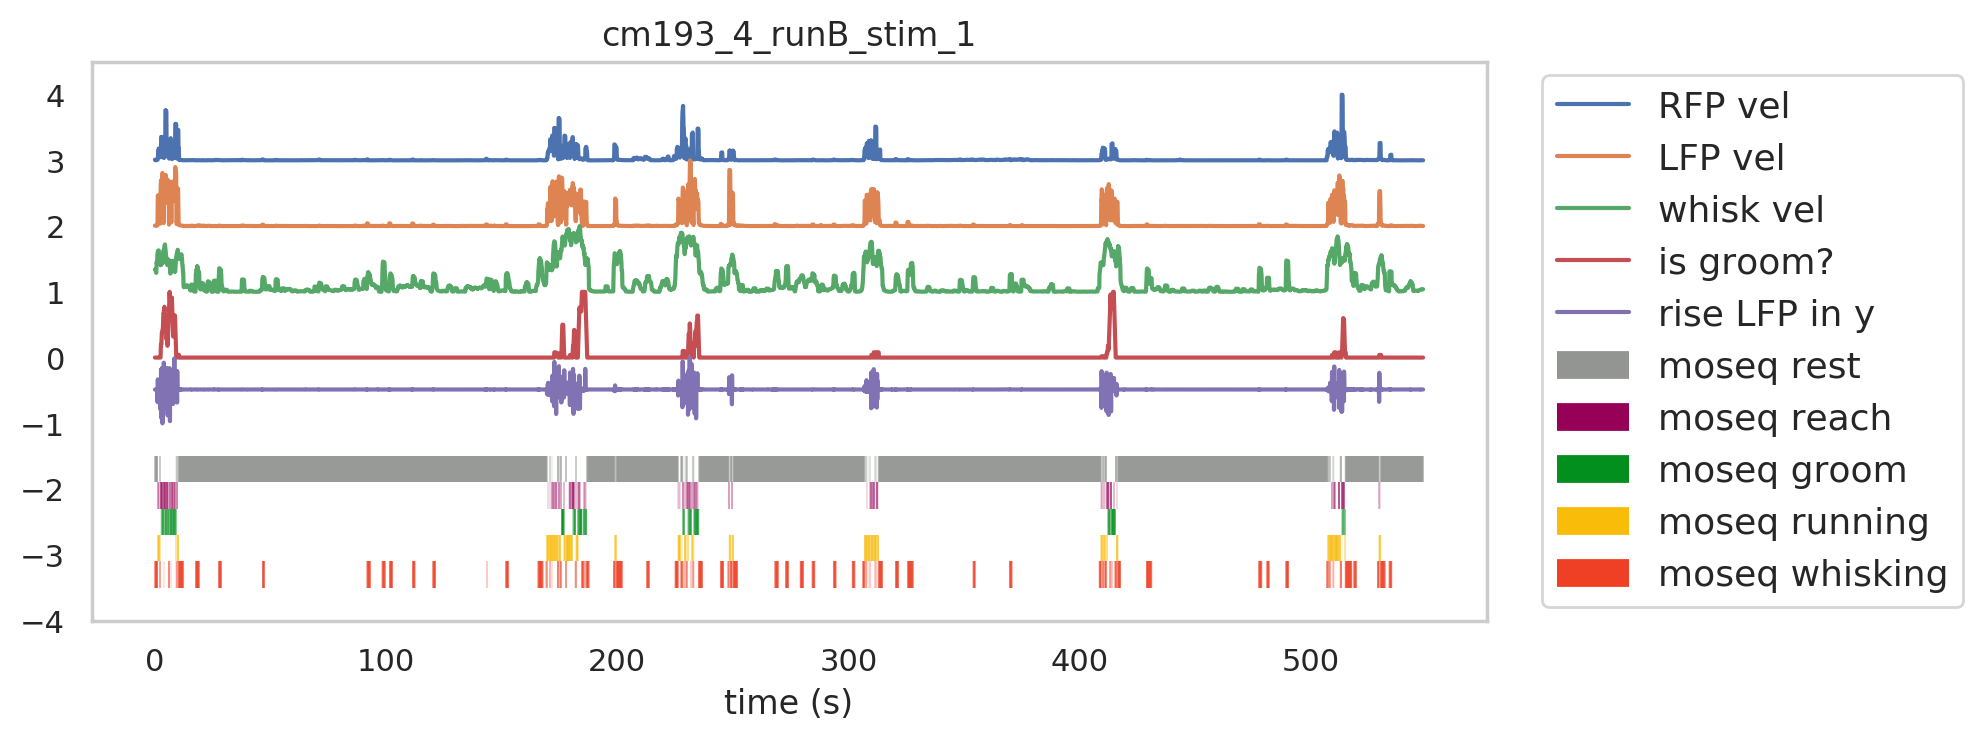

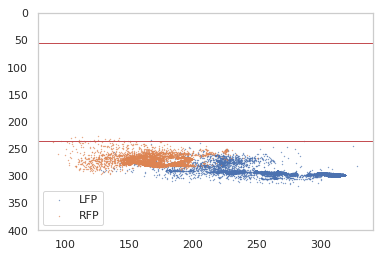

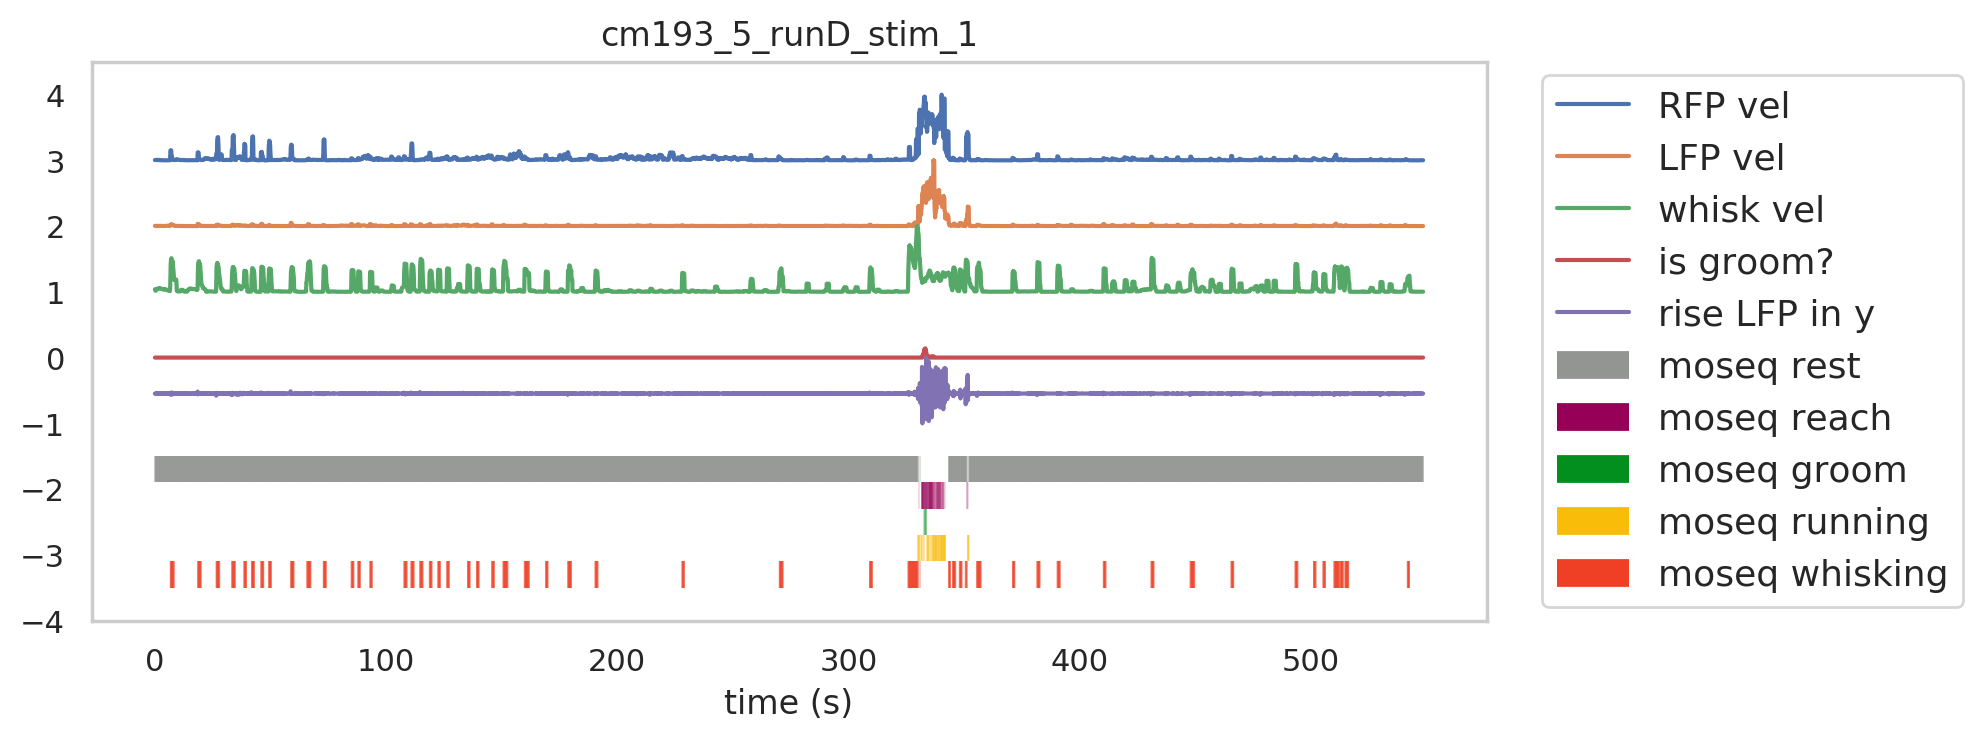

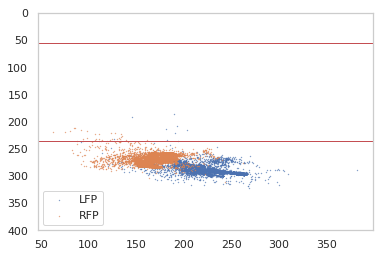

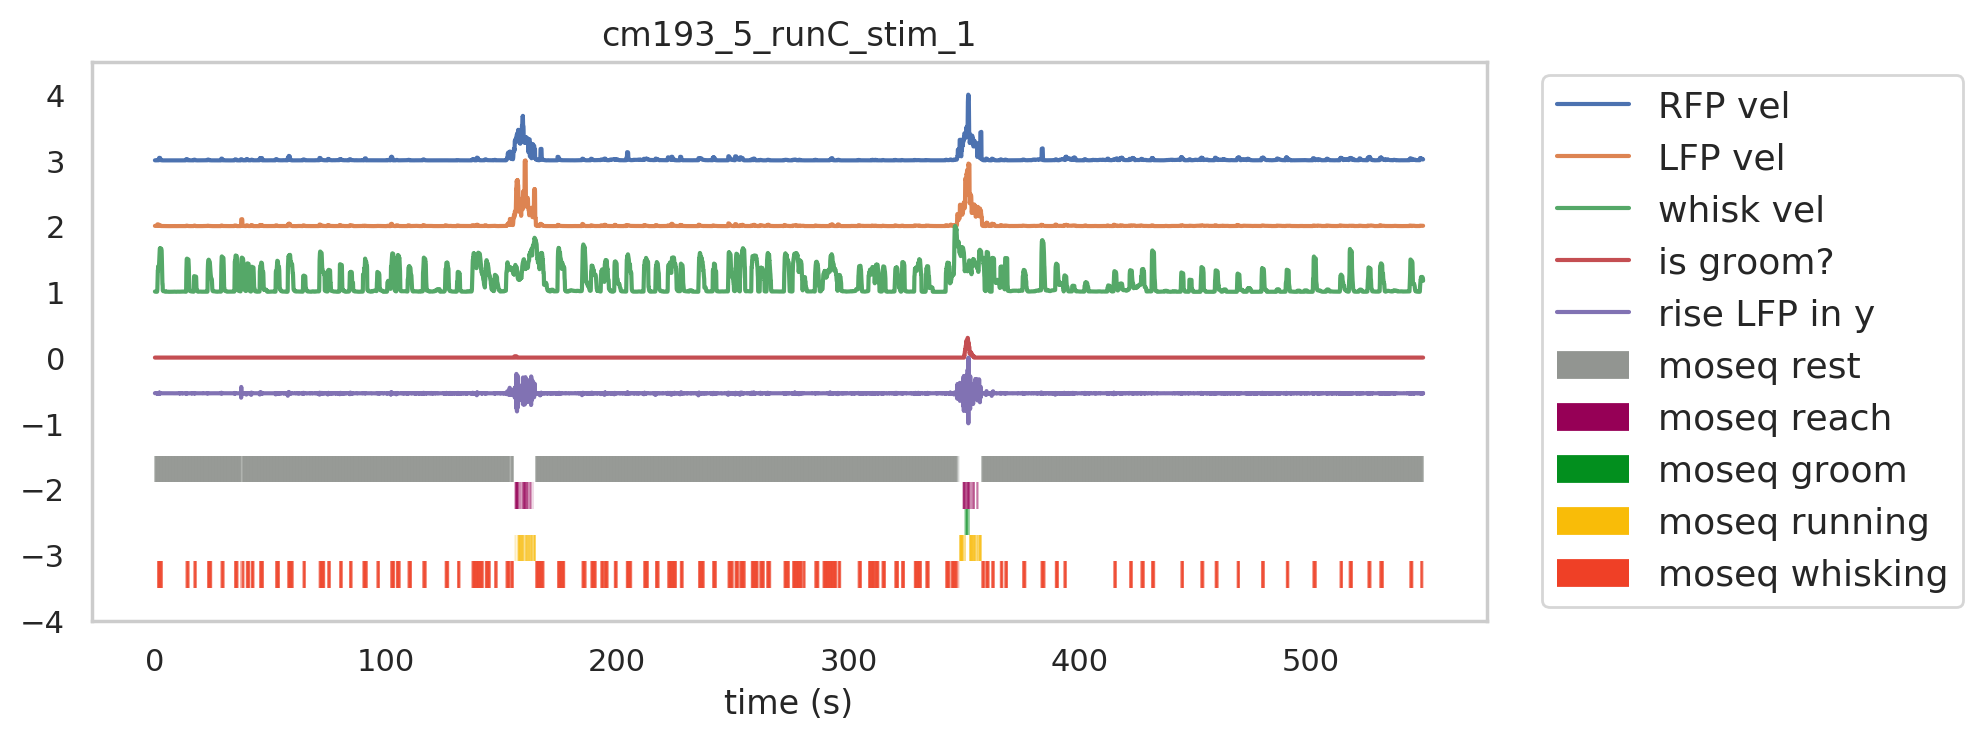

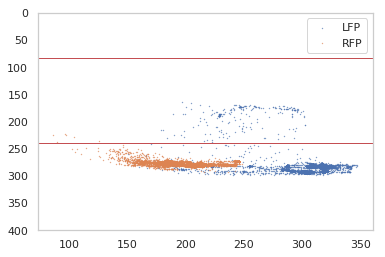

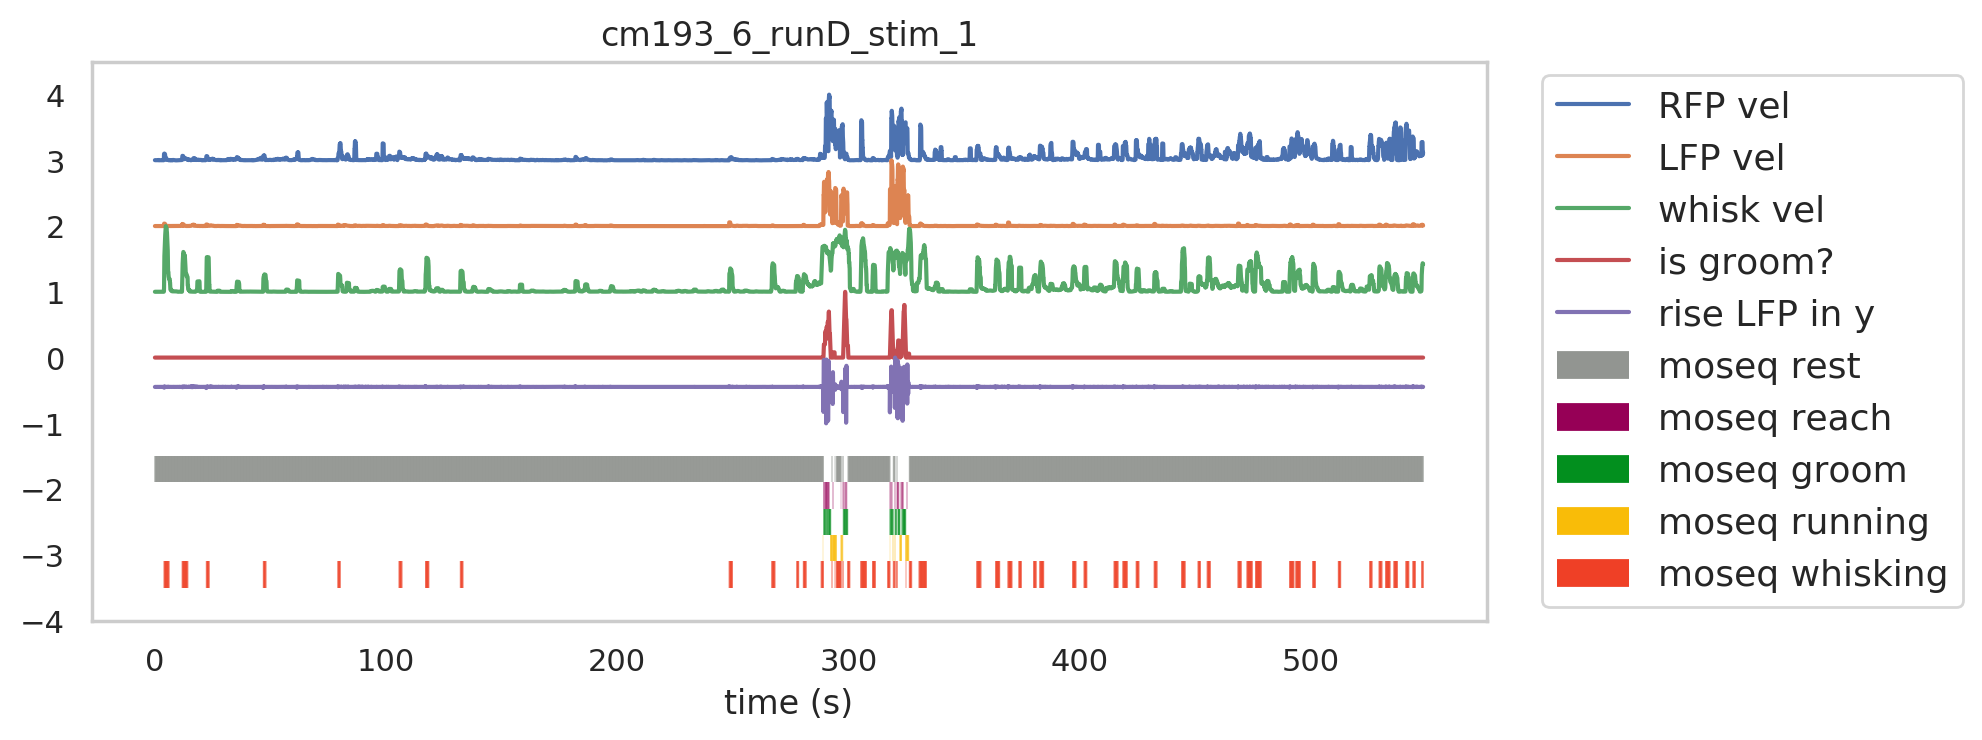

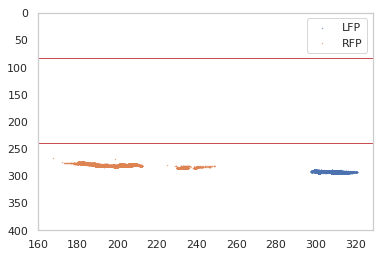

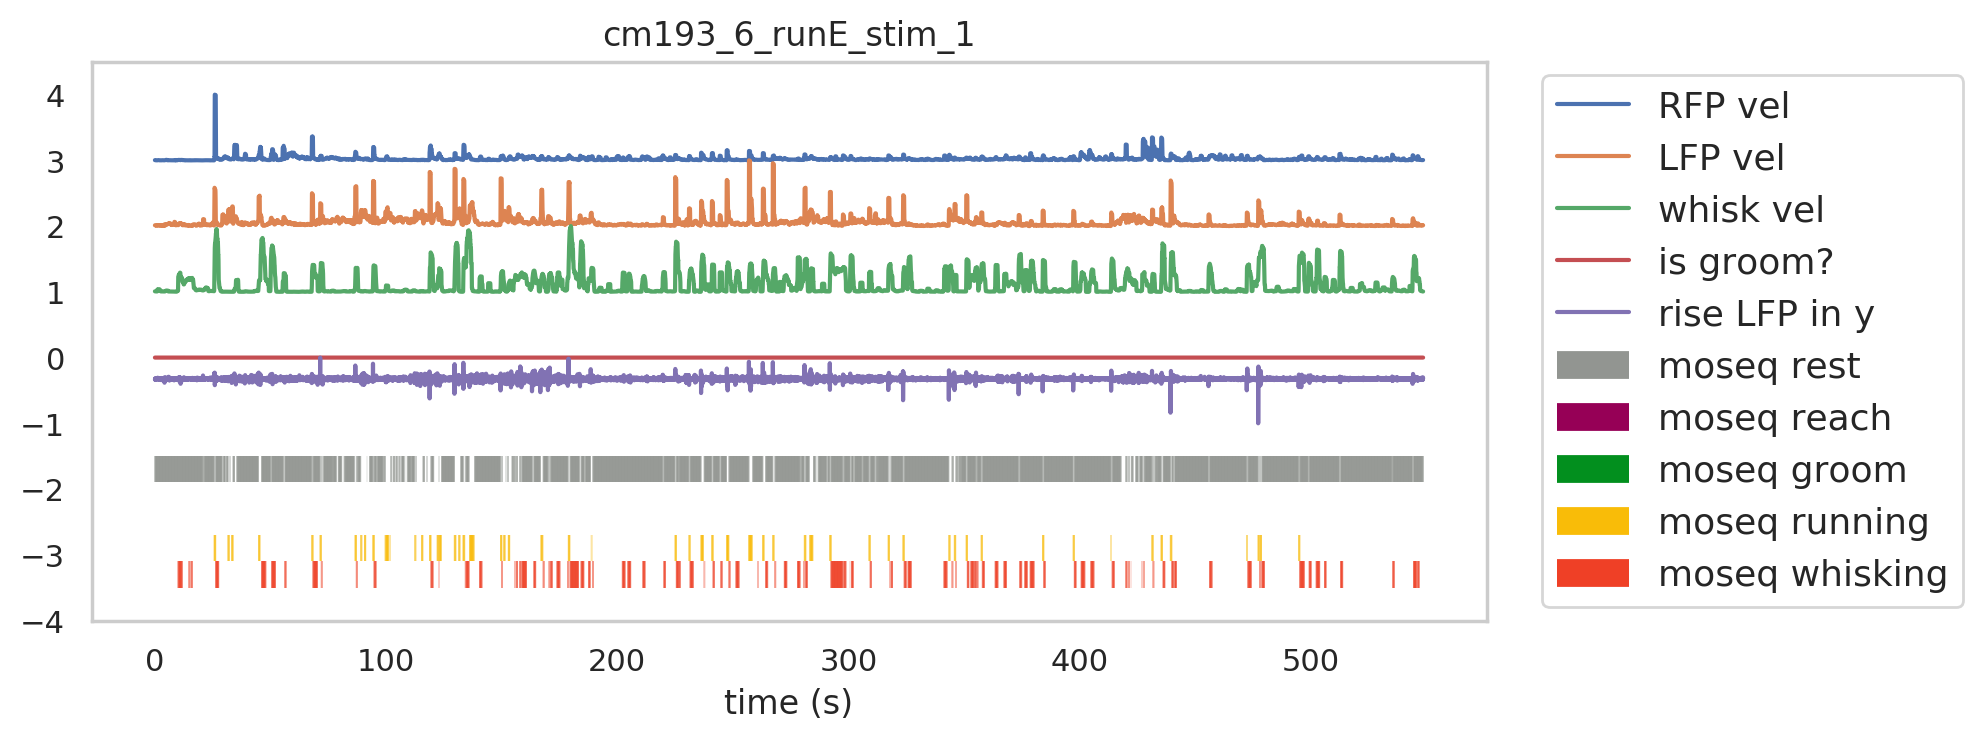

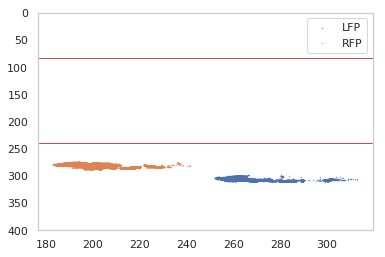

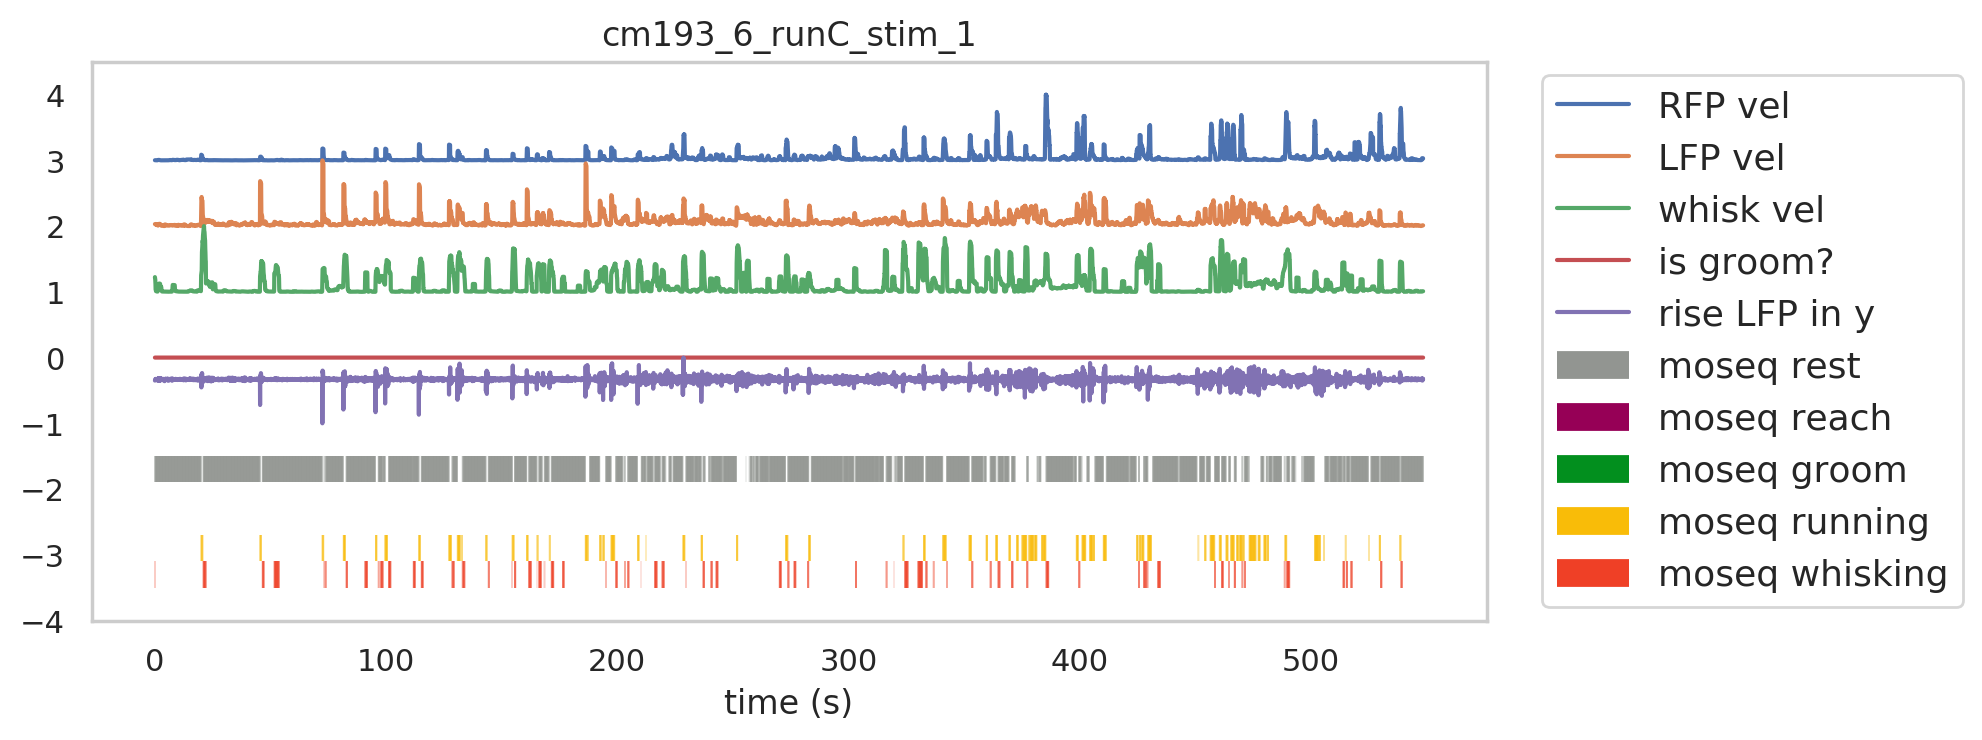

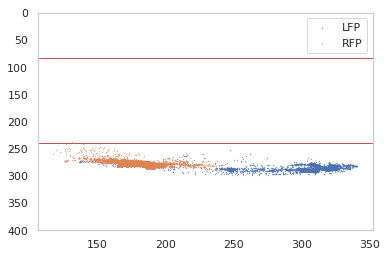

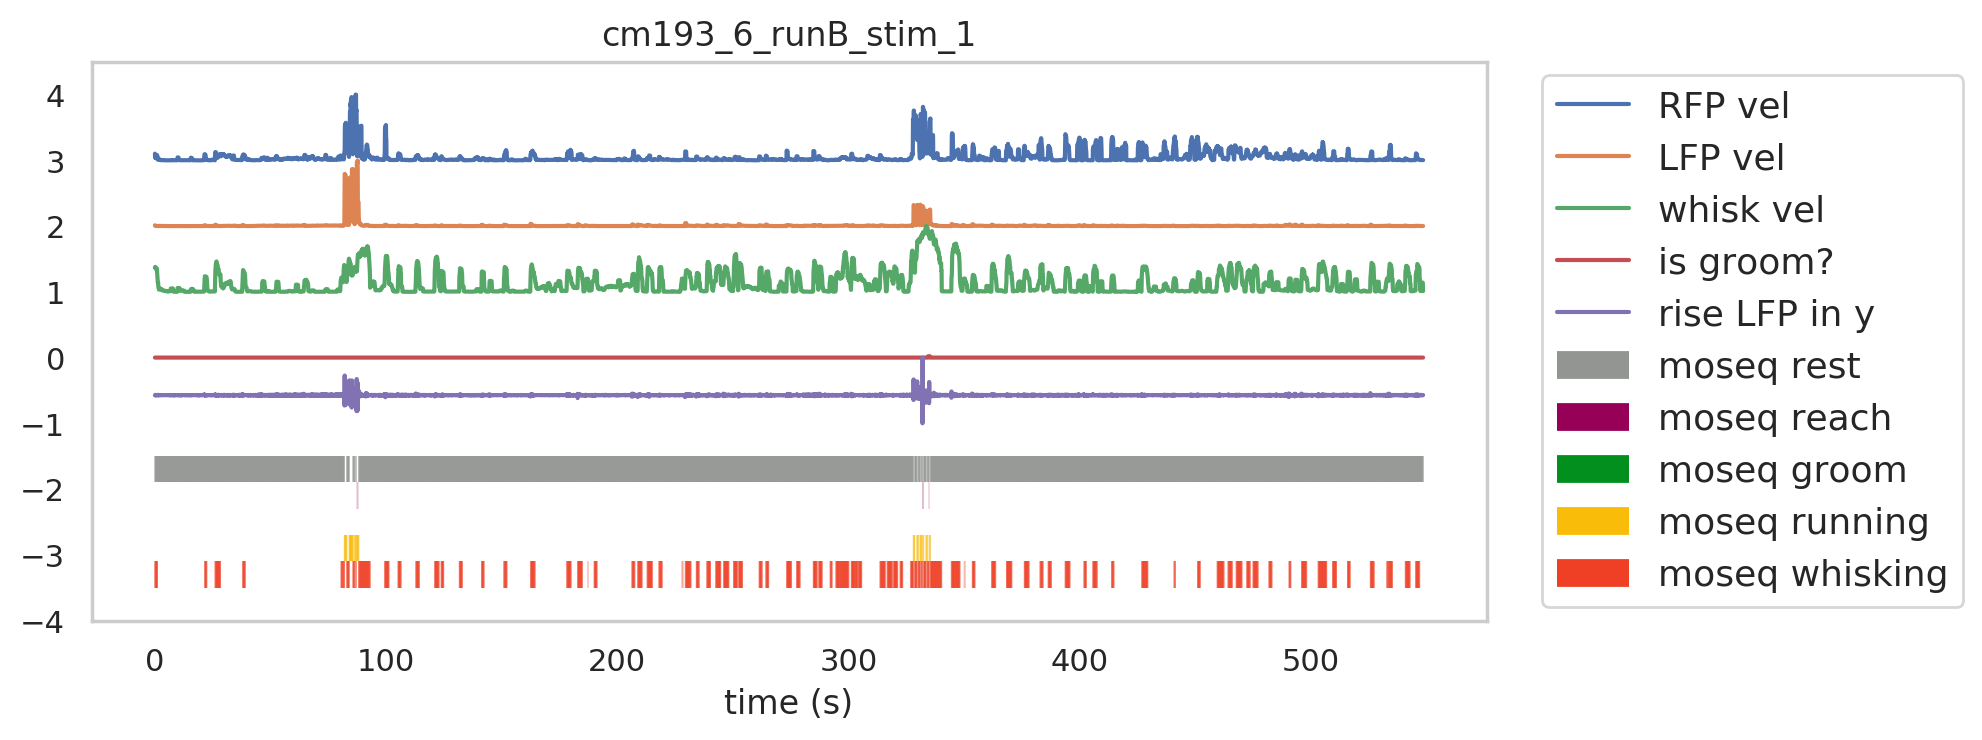

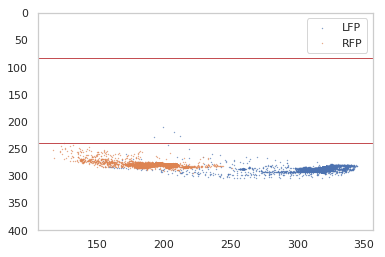

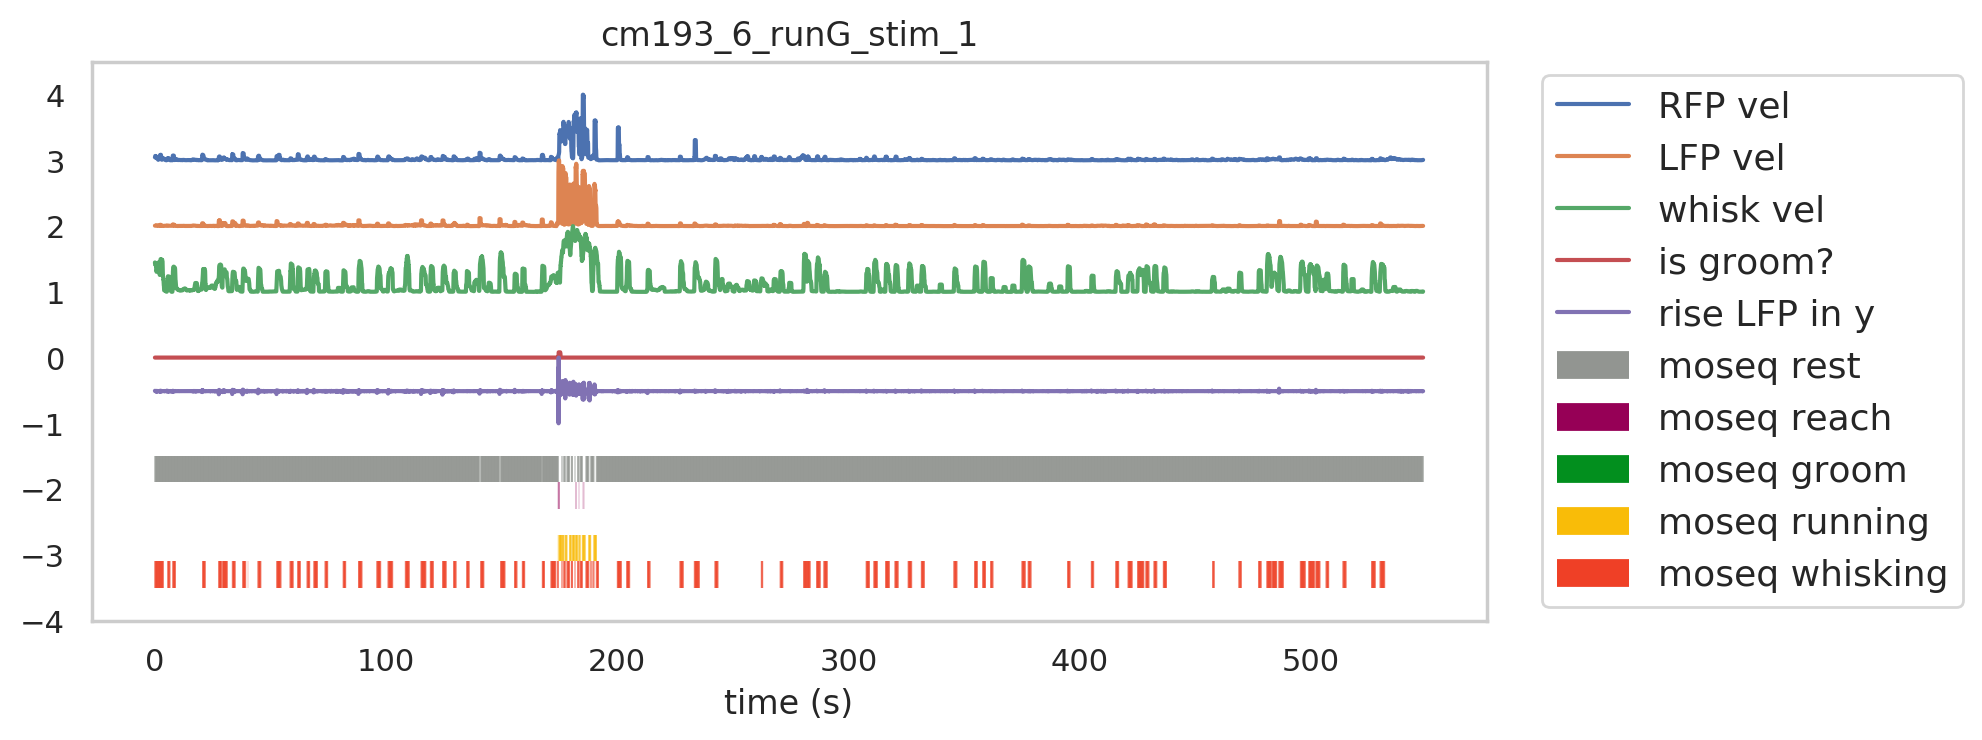

In [78]:
sns.set_style("whitegrid", {'axes.grid' : False})
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

data_joint=pd.DataFrame()
big_df_concat = pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    
    ################################### identity 
    run_name = fname[-15:-4]
    mouse = fname[-23:-18]
    day = fname[-17:-16]
    mouse_day = mouse+'_'+day
    run = fname[-15:-11]

        
    try:    
        f_config = h5py.File(step_0_root+'crop_groom_'+mouse+'.mat','r')

        x_top_left = np.array(f_config[f_config['xx']['groom'][int(day)-1,0]])[:,0]
        x_botton_right = np.array(f_config[f_config['xx']['groom'][int(day)-1,0]])[:,1]
        y_top_left = np.array(f_config[f_config['yy']['groom'][int(day)-1,0]])[:,0]
        y_botton_right = np.array(f_config[f_config['yy']['groom'][int(day)-1,0]])[:,1]

        out_h = int((x_botton_right - x_top_left))
        out_w = int((y_botton_right - y_top_left)) +200
        y = int(x_top_left)
        x = int(y_top_left)-200

        f_name_dlc = glob.glob(body_path + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level

        paws_vel_df = pd.DataFrame()
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        for i_bpt,bpt in enumerate(bodyparts):

            p_value = new_df[bpt]['likelihood']
            new_df[bpt]['x'][p_value<0.05]=np.nan
            new_df[bpt]['y'][p_value<0.05]=np.nan
            new_df[bpt] = new_df[bpt].interpolate()
            new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel).rolling(30).std()
            tocut = vel.shape[0]%3
            if tocut ==0:
                vel = np.mean(vel.values.reshape((-1,3)),axis=1)
            else:
                vel = np.mean(vel[:-tocut].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        LFP_vel = np.array(paws_vel_df['LFP'])
        RFP_vel = np.array(paws_vel_df['RFP'])

        fig,ax = plt.subplots(1)
        plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
        plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')

        rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
        plt.ylim([0,400])
        plt.legend()
        ax.add_patch(rect)
        plt.gca().invert_yaxis()

        rise_LFP = new_df['LFP']['y'].copy().diff().rolling(5).std().rolling(3).mean()
        if tocut ==0:
            rise_LFP = np.mean(rise_LFP.values.reshape((-1,3)),axis=1) #(11980,)
        else:
            rise_LFP = np.mean(rise_LFP[:-tocut].values.reshape((-1,3)),axis=1) #(11980,)
        rise_LFP = rise_LFP[500:-505] 
        # rise_LFP = normalize(stats.zscore(rise_LFP[500:-505]))

        rise_LFP_raw = new_df['LFP']['y'].copy().diff()
        if tocut ==0:
            rise_LFP_raw = np.mean(rise_LFP_raw.values.reshape((-1,3)),axis=1) #(11980,)
        else:
            rise_LFP_raw = np.mean(rise_LFP_raw[:-tocut].values.reshape((-1,3)),axis=1) #(11980,)
        rise_LFP_raw = rise_LFP_raw[500:-505]   

        is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
        is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
        is_groom = np.logical_or(is_groom_LFP,is_groom_RFP)
        is_groom_smooth = is_groom.rolling(50).mean()
        if tocut ==0:
            is_groom_smooth_ds = np.mean(is_groom_smooth.values.reshape((-1,3)),axis=1) #(11980,)
        else:
            is_groom_smooth_ds = np.mean(is_groom_smooth[:-tocut].values.reshape((-1,3)),axis=1) #(11980,)

        is_groom_smooth_ds = is_groom_smooth_ds[500:-505]


    except:
        print('RUN missing ',mouse_day+'_'+run)   
        continue

    
    f_name_dlc = glob.glob(whiskey_path + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

    vel_df = pd.DataFrame()
    for i_bpt,bpt in enumerate(bodyparts):
        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        vel_df[bpt] = vel
    mean_vel = vel_df.mean(axis=1)
    smooth_mean_vel = mean_vel.rolling(60).std()
    smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    whisk_vel = smooth_mean_vel_ds[500:-505]

    LFP_vel_norm = stats.zscore(LFP_vel)
    RFP_vel_norm = stats.zscore(RFP_vel)    
    whisk_vel_norm = stats.zscore(whisk_vel)  
    
    big_df = pd.DataFrame()
    all_bev = ['LFP_vel_norm','RFP_vel_norm','whisk_vel_norm']
    for bev in all_bev:
        exec("big_df[bev] = normalize({})".format(bev))
    big_df['rise_LFP']=rise_LFP
    big_df['is_groom_smooth_ds']=is_groom_smooth_ds
    
    #behavior segmentation
    is_whisking = np.logical_and(big_df['whisk_vel_norm']>0.2, 
                              big_df['LFP_vel_norm']<0.1)
    is_reach = big_df['rise_LFP']>10
    is_groom = np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.1, 
                              big_df['LFP_vel_norm']>0.1),~is_reach)    
    is_running = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['LFP_vel_norm']>0.2),~is_groom),~is_reach)
    is_rest = np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['LFP_vel_norm']<0.1)
    
    moseq_list = ['is_rest','is_reach','is_groom','is_running','is_whisking']
    
    for moseq in moseq_list:
        exec("big_df[moseq] = {}".format(moseq))
        
    tmp = pd.concat([big_df], keys=[mouse_day+'_'+run], names=['row_level'])
    big_df_concat = big_df_concat.append(tmp)


    plt.figure(figsize=(9,3.7),dpi=200)
    T=LFP_vel_norm.shape[0]
    t_ax=np.divide(range(T),20)
                         
    plt.plot(t_ax,normalize(RFP_vel_norm)+3,label='RFP vel')            
    plt.plot(t_ax,normalize(LFP_vel_norm)+2,label='LFP vel')
    plt.plot(t_ax,normalize(whisk_vel_norm)+1,label='whisk vel')
    plt.plot(t_ax,is_groom_smooth_ds,label='is groom?')
    plt.plot(t_ax,normalize(rise_LFP_raw)-1,label='rise LFP in y')
    plt.xlabel('time (s)')
    col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
    col_list_palette = sns.xkcd_palette(col_list)
    
    # moseq
    for i, moseq in enumerate(moseq_list):
        plt.vlines(t_ax[np.where(big_df[moseq]==True)], -1.5-i*0.4, -1.9-i*0.4,linewidth=0.1,color=col_list_palette[i])
        plt.vlines(t_ax[0], 8, 9,linewidth=10,color=col_list_palette[i],label='moseq '+moseq[3:])#for the legend

    plt.ylim([-4,4.5])
    plt.title(mouse_day+'_'+run_name)
    plt.legend(bbox_to_anchor=(1.04,0.5), loc="center left", borderaxespad=0,fontsize = 13)

    

In [35]:
save_root = str(PREPARES / "behavior-segment") + "/"
save_pickle(big_df_concat,save_root+'big_df_concat_'+mouse)

In [55]:
big_df_concat

face_pc   body_pc  whisk_vel_norm  nose_vel_norm  \
row_level                                                               
cm125_3_runG 0      0.241361  0.025528        0.015603       0.145829   
             1      0.342061  0.019103        0.017364       0.144238   
             2      0.358116  0.019194        0.018450       0.182833   
             3      0.408185  0.029218        0.019596       0.196265   
             4      0.420270  0.026962        0.024601       0.200186   
...                      ...       ...             ...            ...   
cm125_2_runB 10970  0.052148  0.007278        0.040534       0.098874   
             10971  0.029464  0.002976        0.039760       0.083985   
             10972  0.027849  0.000961        0.032165       0.078986   
             10973  0.024817  0.001068        0.032170       0.071988   
             10974  0.019359  0.000988        0.031448       0.058615   

                    pupil_pc_norm  LFP_vel_norm  RFP_vel_norm  \
row_level                                                       
cm125_3_runG 0           0.582588      0.004263      0.009193   
             1           0.578768      0.004276      0.009221   
             2           0.589507      0.004266      0.009298   
             3           0.581517      0.004793      0.009319   
             4           0.595146      0.004779      0.009204   
...                           ...           ...           ...   
cm125_2_runB 10970       0.447909      0.002599      0.003328   
             10971       0.428627      0.002362      0.003439   
             10972       0.417665      0.002303      0.003430   
             10973       0.410568      0.002132      0.003115   
             10974       0.397514      0.002072      0.003029   

                    mirrorLFP_vel_norm  mirrorRFP_vel_norm  \
row_level                                                    
cm125_3_runG 0                0.004478            0.005800   
             1                0.004277            0.006084   
             2                0.004021            0.006330   
             3                0.003847            0.006638   
             4                0.003952            0.006719   
...                                ...                 ...   
cm125_2_runB 10970            0.005481            0.010769   
             10971            0.005631            0.010854   
             10972            0.005722            0.011848   
             10973            0.005884            0.011955   
             10974            0.005872            0.012269   

                    mirrorLHP_vel_norm  mirrorRHP_vel_norm   rot_raw  \
row_level                                                              
cm125_3_runG 0                0.006547            0.004363  0.009154   
             1                0.006685            0.004213  0.008852   
             2                0.006458            0.003465  0.008852   
             3                0.006216            0.003351  0.008852   
             4                0.006689            0.003636  0.008852   
...                                ...                 ...       ...   
cm125_2_runB 10970            0.795455            0.012469  0.018706   
             10971            0.808985            0.012226  0.017856   
             10972            0.876326            0.012150  0.017927   
             10973            0.876251            0.011807  0.018001   
             10974            0.889926            0.011101  0.018213   

                    rise_LFP  is_groom_smooth_ds  is_rest  is_whisking  \
row_level                                                                
cm125_3_runG 0      0.283039                 0.0     True        False   
             1      0.316835                 0.0     True        False   
             2      0.066827                 0.0     True        False   
             3      0.154845                 0.0     True        False   
             4      0.273069         